# 04 Calibration, Explainability, and Risk Tiers

This notebook makes the best model's probabilities more trustworthy, explains individual predictions with SHAP, and turns calibrated probabilities into practical support tiers.

### What and why
Reload the comparison and rebuild the selected pipeline so this notebook can run independently after notebook 03. The same selection rule prioritizes recall and then PR-AUC.

In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import shap
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss
from data_utils import load_data, prepare_model_data, split_data
from model_utils import make_pipeline
from plot_utils import set_style, save_figure

set_style()
data = load_data()
model_data = prepare_model_data(data)
X_train, X_test, y_train, y_test = split_data(model_data)
comparison = pd.read_csv("../results/tables/model_comparison.csv")
best_row = comparison.sort_values(["recall", "pr_auc"], ascending=False).iloc[0]
best_key = (best_row["model"], best_row["imbalance_strategy"])
base_model = make_pipeline(best_key[0], X_train.columns, best_key[1])
base_model.fit(X_train, y_train)


,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](40,)","['Marital status','Application mode','Application order',..., '2nd_sem_approval_rate','grade_change','financial_risk_flag']"
n_features_in_,int,40
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


### What and why
Compare the original probabilities with Platt sigmoid calibration and isotonic calibration. Brier score rewards probabilities that are close to actual outcomes, not just good rankings.

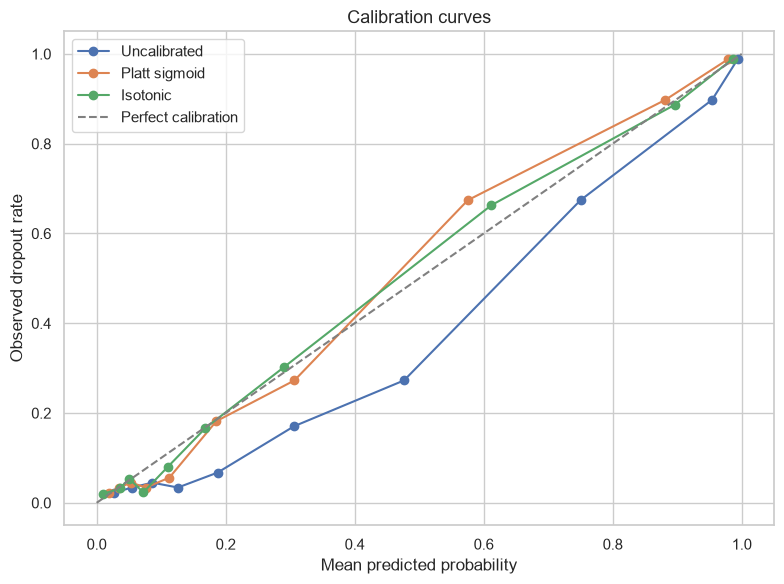

,method,brier_score
2,Isotonic,0.0842
1,Platt sigmoid,0.0855
0,Uncalibrated,0.0932


In [2]:
calibrated_sigmoid = CalibratedClassifierCV(estimator=make_pipeline(best_key[0], X_train.columns, best_key[1]), method="sigmoid", cv=5)
calibrated_isotonic = CalibratedClassifierCV(estimator=make_pipeline(best_key[0], X_train.columns, best_key[1]), method="isotonic", cv=5)
calibrated_sigmoid.fit(X_train, y_train)
calibrated_isotonic.fit(X_train, y_train)

probability_models = {
    "Uncalibrated": base_model,
    "Platt sigmoid": calibrated_sigmoid,
    "Isotonic": calibrated_isotonic,
}
calibration_rows = []
plt.figure(figsize=(8, 6))
for label, model in probability_models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    fraction_positive, mean_predicted = calibration_curve(y_test, probabilities, n_bins=10, strategy="quantile")
    plt.plot(mean_predicted, fraction_positive, marker="o", label=label)
    calibration_rows.append({"method": label, "brier_score": brier_score_loss(y_test, probabilities)})
plt.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
plt.title("Calibration curves")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed dropout rate")
plt.legend()
save_figure("fig09_calibration_curve.png")
plt.show()
calibration_scores = pd.DataFrame(calibration_rows).sort_values("brier_score")
calibration_scores.to_csv("../results/tables/calibration_scores.csv", index=False)
display(calibration_scores.round(4))


### What and why
Select the calibrated model with the lowest Brier score for the remaining explanation and risk-tier analysis.

In [3]:
best_method = calibration_scores.iloc[0]["method"]
final_model = probability_models[best_method]
print("Selected calibrated model:", best_method)


Selected calibrated model: Isotonic


### What and why
Transform features once and use SHAP on the fitted estimator. The summary and bar plots show global directions and importance; the three waterfall plots show individual high, medium, and low-risk explanations.

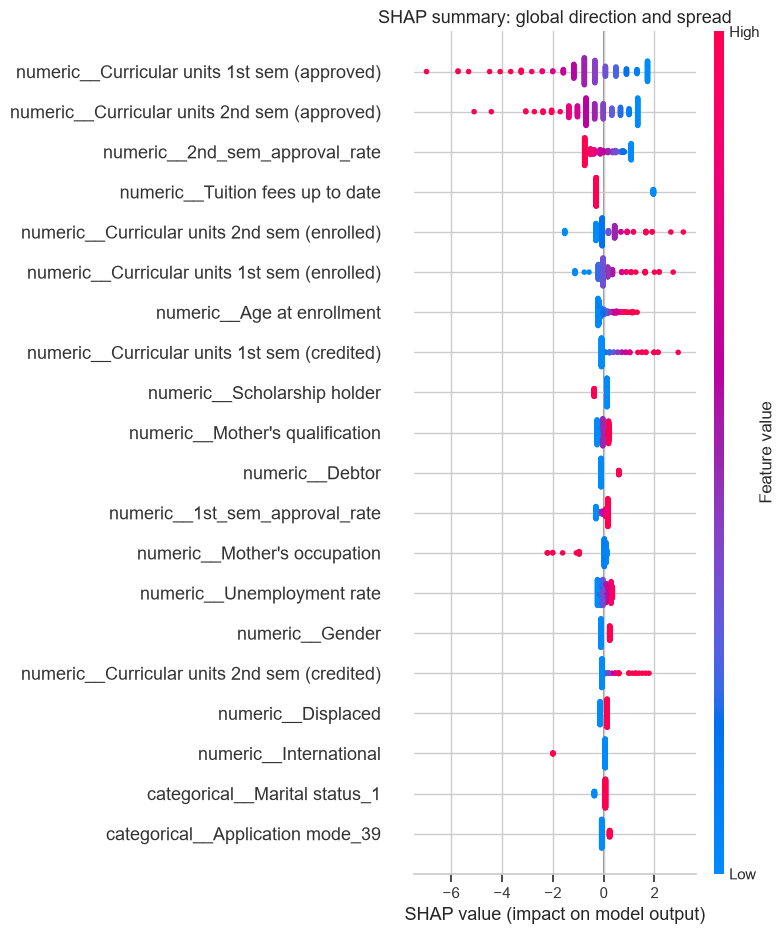

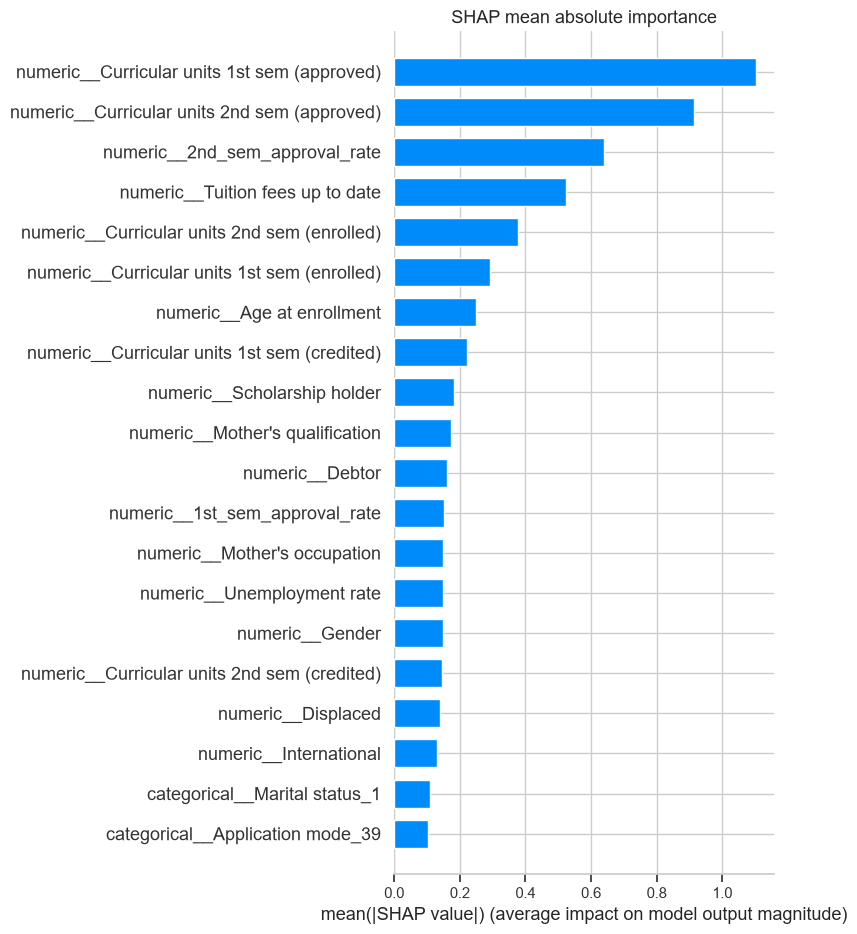

In [4]:
preprocessor = base_model.named_steps["preprocess"]
transformed_train = preprocessor.transform(X_train)
transformed_test = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
estimator = base_model.named_steps["model"]
background = transformed_train[:100]
explainer = shap.Explainer(estimator, background, feature_names=feature_names)
shap_values = explainer(transformed_test[:200])

shap.summary_plot(shap_values, transformed_test[:200], feature_names=feature_names, show=False)
plt.title("SHAP summary: global direction and spread")
save_figure("fig10_shap_summary.png")
plt.show()
shap.summary_plot(shap_values, transformed_test[:200], feature_names=feature_names, plot_type="bar", show=False)
plt.title("SHAP mean absolute importance")
save_figure("fig11_shap_bar.png")
plt.show()


### What and why
Assign Low, Medium, and High tiers using the requested calibrated thresholds. Report the observed dropout rate within each tier and attach a proportionate intervention.

In [5]:
final_probabilities = final_model.predict_proba(X_test)[:, 1]
tiers = pd.cut(
    final_probabilities,
    bins=[-np.inf, 0.30, 0.60, np.inf],
    labels=["Low", "Medium", "High"],
    right=True,
)
tier_table = pd.DataFrame({"tier": tiers, "dropout": y_test.to_numpy()}).groupby("tier", observed=False).agg(
    students=("dropout", "size"), real_dropout_rate=("dropout", "mean")
)
tier_table["suggested_action"] = [
    "Routine check-in and normal academic resources",
    "Advisor meeting and targeted academic/financial support",
    "Prompt advisor outreach, financial review, and intensive support plan",
]
tier_table.to_csv("../results/tables/risk_tier_summary.csv")
display(tier_table)


,students,real_dropout_rate,suggested_action
tier,,,
Low,578,0.074394,Routine check-in and normal academic resources
Medium,86,0.488372,Advisor meeting and targeted academic/financia...
High,221,0.900452,"Prompt advisor outreach, financial review, and..."


### What and why
Choose three test students at different risk levels and create waterfall plots. The top five absolute SHAP factors are printed in plain English so the explanation can be discussed in a viva.

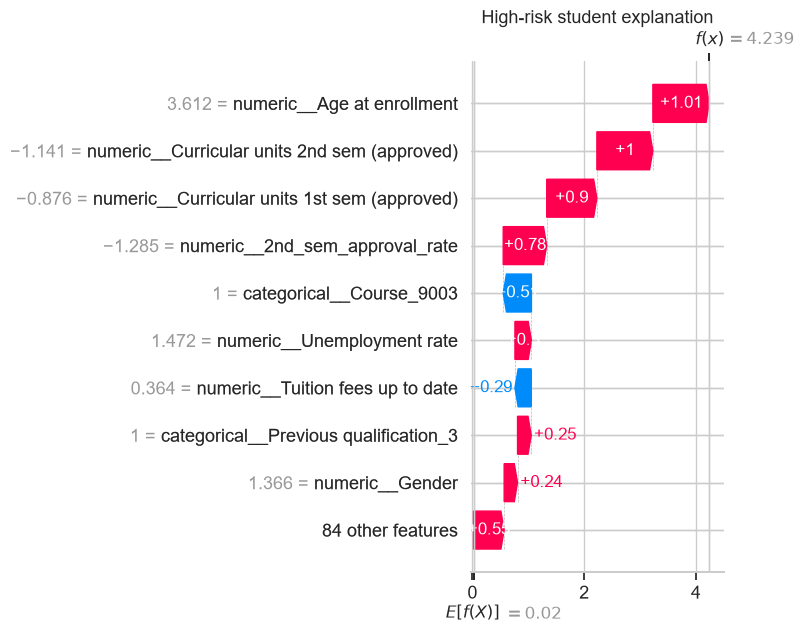


High-risk student, predicted dropout probability=0.98
- numeric__Age at enrollment increased the model score.
- numeric__Curricular units 2nd sem (approved) increased the model score.
- numeric__Curricular units 1st sem (approved) increased the model score.
- numeric__2nd_sem_approval_rate increased the model score.
- categorical__Course_9003 decreased the model score.


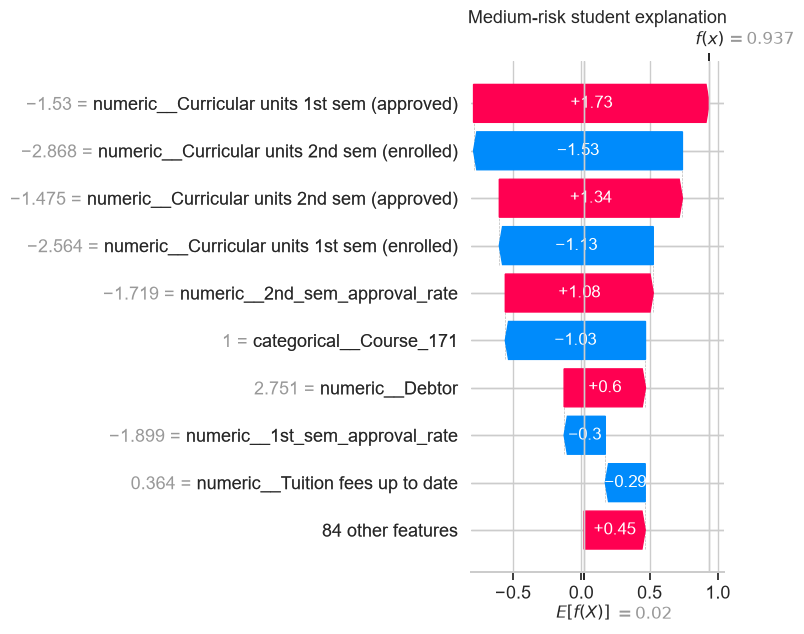


Medium-risk student, predicted dropout probability=0.58
- numeric__Curricular units 1st sem (approved) increased the model score.
- numeric__Curricular units 2nd sem (enrolled) decreased the model score.
- numeric__Curricular units 2nd sem (approved) increased the model score.
- numeric__Curricular units 1st sem (enrolled) decreased the model score.
- numeric__2nd_sem_approval_rate increased the model score.


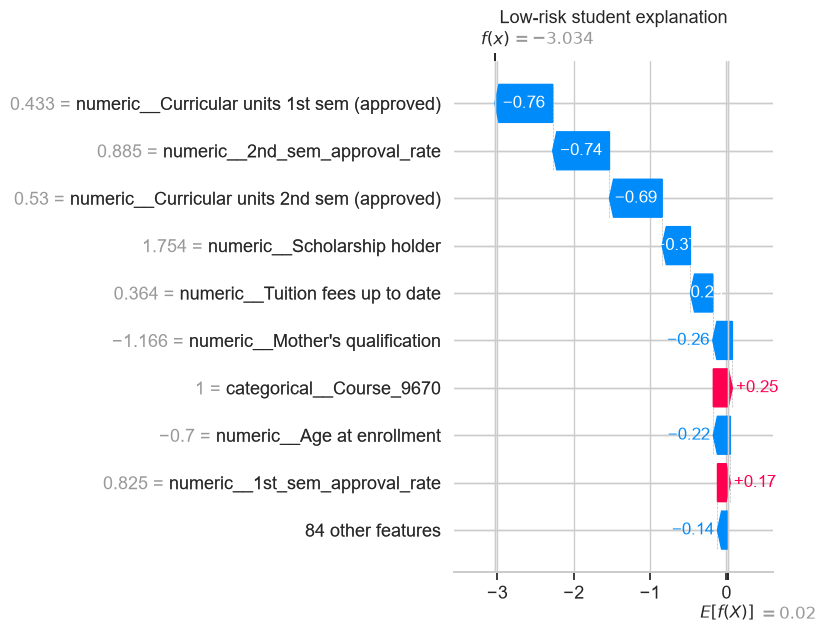


Low-risk student, predicted dropout probability=0.02
- numeric__Curricular units 1st sem (approved) decreased the model score.
- numeric__2nd_sem_approval_rate decreased the model score.
- numeric__Curricular units 2nd sem (approved) decreased the model score.
- numeric__Scholarship holder decreased the model score.
- numeric__Tuition fees up to date decreased the model score.


In [6]:
tier_order = {"High": 2, "Medium": 1, "Low": 0}
selected_indices = []
for tier_name in ["High", "Medium", "Low"]:
    matches = np.where(tiers.astype(str) == tier_name)[0]
    if len(matches):
        selected_indices.append(matches[0])

for position, index in enumerate(selected_indices):
    explanation = explainer(transformed_test[index:index + 1])[0]
    shap.plots.waterfall(explanation, max_display=10, show=False)
    plt.title(f"{tiers[index]}-risk student explanation")
    save_figure(f"fig{12 + position:02d}_shap_waterfall_{str(tiers[index]).lower()}.png")
    plt.show()
    top = np.argsort(np.abs(explanation.values))[-5:][::-1]
    print(f"\n{tiers[index]}-risk student, predicted dropout probability={final_probabilities[index]:.2f}")
    for feature_index in top:
        direction = "increased" if explanation.values[feature_index] > 0 else "decreased"
        print(f"- {feature_names[feature_index]} {direction} the model score.")


## Conclusion

Calibration makes the probability more meaningful, SHAP makes the prediction auditable, and the three tiers connect risk to action. These outputs support human decision-making; they should not replace advisor judgement or be used as automatic punishment.